# 06 — Topics + Association rules (Phase 3 ส่วนที่ 3)

**คำถาม:** นอกจาก 4 aspect ที่เรากำหนดเอง คนพูดถึงเรื่องอะไรอีก และเรื่องไหนที่มาพร้อมกับรีวิวดาวต่ำ

ส่วนนี้ **ไม่ต้องใช้ label** จึงทำได้เลยระหว่างรอ label aspect และผลจาก Colab
ใช้ประโยคและ embedding (bge-m3) ชุดเดียวกับ `05_aspects` ซึ่งเก็บไว้ใน `data/interim/` (รัน 05 ก่อน)

**BERTopic ทำงานอย่างไร** (แต่ละขั้นเป็นเทคนิค data mining ที่อธิบายแยกได้)
1. **Embedding:** ประโยค → vector 1,024 มิติ (มีแล้วจาก 05)
2. **UMAP:** ลดเหลือ 5 มิติ โดยพยายามรักษาว่าอะไรอยู่ใกล้อะไร เพราะการ cluster ในมิติสูงมากทำงานได้แย่ (ระยะห่างระหว่างทุกคู่จะคล้ายกันไปหมด)
3. **HDBSCAN:** clustering แบบดูความหนาแน่น ไม่ต้องกำหนดจำนวน cluster ล่วงหน้า และ **ยอมไม่จัดกลุ่ม** จุดที่ไม่หนาแน่นพอ (topic `-1` = outlier)
4. **c-TF-IDF:** หาคำที่เด่นในแต่ละ cluster เมื่อเทียบกับ cluster อื่น ใช้เป็นชื่อ topic

**เรื่อง "แนวโน้ม":** Wongnai ไม่มีวันที่ของรีวิว จึงทำ trend ตามเวลาไม่ได้ (ตามที่บันทึกไว้ใน README)
ตรงนี้จึงดูความสัมพันธ์กับ **ดาว** แทน trend จริงต้องรอข้อมูลที่มีวันที่ (เช่นข้อความจาก LINE bot)

In [1]:
import sys, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.aspects import ASPECTS, ASPECT_NAMES_TH
from src.viz import use_thai_font

FIGS = ROOT / "reports" / "figures"
INTERIM = ROOT / "data" / "interim"
use_thai_font()

sents = pd.read_parquet(INTERIM / "sentences.parquet")
emb = np.load(INTERIM / f"bge_m3_{len(sents)}.npy")
assert len(sents) == len(emb)
print(f"{len(sents):,} sentences from {sents.review_id.nunique():,} reviews, embeddings {emb.shape}")

29,286 sentences from 2,000 reviews, embeddings (29286, 1024)


## 1. ตัดคำสำหรับ c-TF-IDF

c-TF-IDF ต้องการ "คำ" แต่ภาษาไทยไม่เว้นวรรคระหว่างคำ จึงส่ง tokenizer ของ PyThaiNLP ให้ `CountVectorizer`
และตัด stopword กับคำที่เจอทุกที่ ("ร้าน", "ค่ะ", "ครับ") ไม่งั้นจะขึ้นเป็นคำเด่นของทุก topic
(ต่างจาก baseline ที่ **เก็บ** "ไม่" ไว้ เพราะตรงนี้เราต้องการคำที่บอก **หัวข้อ** ไม่ใช่ sentiment)

In [2]:
from pythainlp.tokenize import word_tokenize
from pythainlp.corpus.common import thai_stopwords

STOP = set(thai_stopwords()) | {"ร้าน", "ค่ะ", "ครับ", "คะ", "นะคะ", "นะ", "จ้า", "เลย", "มาก", "ๆ"}

def topic_tokens(text):
    return [w for w in word_tokenize(text.lower())
            if w not in STOP and len(w) > 1 and any(c.isalpha() for c in w)]

topic_tokens("ร้านนี้ที่จอดรถหายากมากค่ะ ต้องไปจอดฝั่งตรงข้าม")

['ที่จอดรถ', 'หา', 'จอด', 'ฝั่ง', 'ตรงข้าม']

## 2. BERTopic

- `min_cluster_size=80`: topic ต้องมีอย่างน้อย 80 ประโยค ค่าน้อยจะได้ topic ย่อยเยอะจนอ่านไม่ไหว ค่ามากจะรวมเรื่องที่ต่างกันเข้าด้วยกัน
- `random_state=42` ใน UMAP: UMAP มีการสุ่ม ถ้าไม่ fix ไว้ รันแต่ละครั้งจะได้ topic ไม่เหมือนกัน

**กับดักที่เจอ:** รอบแรก topic ทุกตัวมีชื่อเป็นภาษาอังกฤษ ("service, set, cheese, french") ทั้งที่ประโยคเป็นภาษาไทย
สาเหตุคือ BERTopic ตั้งค่า default เป็น `language="english"` ซึ่ง **ลบทุกตัวอักษรที่ไม่ใช่ A–Z** ก่อนหาคำเด่น ภาษาไทยหายหมดโดยไม่มี error เตือน
ส่วน clustering ไม่ได้รับผลกระทบเพราะใช้ embedding (ตัวอย่างประโยคในแต่ละ topic ยังเข้ากลุ่มกันดี) แก้ด้วย `language="multilingual"`

In [3]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

topic_model = BERTopic(
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
    hdbscan_model=HDBSCAN(min_cluster_size=80, min_samples=10, prediction_data=True),
    vectorizer_model=CountVectorizer(tokenizer=topic_tokens, token_pattern=None, lowercase=False, min_df=5),
    top_n_words=8,
    language="multilingual",   # default "english" strips every non A-Z character before extracting keywords
)
sents["topic"], _ = topic_model.fit_transform(sents.sentence.tolist(), embeddings=emb)

info = topic_model.get_topic_info()
print(f"{len(info) - 1} topics, outliers (topic -1): {(sents.topic == -1).mean():.0%} of sentences")

/Users/riewta/Downloads/mlproj/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1128 02:07:56.904000 58710 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


72 topics, outliers (topic -1): 46% of sentences


**46% ของประโยคเป็น outlier** ซึ่งปกติมากสำหรับ HDBSCAN กับข้อความสั้น ประโยคพวก "วันนี้มากับเพื่อน" ไม่ได้อยู่ใกล้ใครพอจะเป็นกลุ่ม
มีคำสั่ง `reduce_outliers()` ไว้บังคับยัดเข้ากลุ่มที่ใกล้ที่สุดได้ แต่จะทำให้ topic ปนกันมากขึ้น ตรงนี้เลือกยอมรับ outlier ไว้

**คอลัมน์ในตาราง**
- `negative`: สัดส่วนประโยคที่ baseline ทายว่าลบ (เป็นการทายระดับประโยค ยังไม่ได้ตรวจสอบ)
- `mean_stars`: ดาวเฉลี่ยของรีวิวที่ประโยคมาจาก (มาจากข้อมูลจริง แต่เป็นระดับรีวิว) ค่าเฉลี่ยของทุกประโยคคือ ~2.9 (เส้นประในกราฟ) ไม่ใช่ 3.0 พอดี เพราะรีวิวดาวต่ำยาวกว่า จึงมีประโยคมากกว่า
- 4 คอลัมน์ aspect: สัดส่วนประโยคใน topic ที่ติด keyword ของ aspect นั้น

In [4]:
def top_words(t, n=5):
    return ", ".join(w for w, _ in topic_model.get_topic(t)[:n])

stats = (sents[sents.topic != -1]
         .groupby("topic")
         .agg(size=("sentence", "size"),
              negative=("p_pos", lambda p: (p < 0.5).mean()),
              mean_stars=("stars", "mean"),
              **{ASPECT_NAMES_TH[a]: (f"kw_{a}", "mean") for a in ASPECTS}))
stats.insert(0, "words", [top_words(t) for t in stats.index])
stats.sort_values("size", ascending=False).head(25).round(2)

,words,size,negative,mean_stars,อาหาร/รสชาติ,ราคา/ความคุ้มค่า,บริการ,บรรยากาศ/สถานที่
topic,,,,,,,,
0,"บาท, ราคา, แพง, เทียบ, คุ้ม",2001,0.13,2.94,0.12,0.86,0.04,0.02
1,"แวะ, ปี, ลอง, ทาน, กิน",599,0.04,3.00,0.08,0.02,0.03,0.02
2,"จืด, เค็ม, แห้ง, แข็ง, เหนียว",596,0.41,2.15,0.60,0.03,0.02,0.03
3,"รสชาติ, อร่อย, แย่, ผิดหวัง, อาหาร",547,0.58,1.94,0.67,0.04,0.05,0.01
4,"เค้ก, ไอศกรีม, ขนม, มะพร้าว, ไอติม",480,0.01,3.53,0.27,0.02,0.05,0.03
5,"ผิดหวัง, งง, เสียดาย, เสียความรู้สึก, แย่มาก",416,0.43,1.89,0.01,0.02,0.01,0.00
6,"พนักงาน, ลูกค้า, บริการ, สนใจ, แย่",395,0.52,1.74,0.00,0.03,0.62,0.06
7,"ไม่ต้อง, หวาน, เผ็ด, เกินไป, ปรุง",379,0.18,3.21,0.47,0.01,0.01,0.02
8,"นั่ง, แอร์, ที่นั่ง, ห้อง, โซน",376,0.02,3.23,0.01,0.01,0.04,0.47


In [5]:
def examples(t, n=4):
    return sents.sentence[sents.topic == t].sample(min(n, (sents.topic == t).sum()), random_state=0).str[:90].tolist()

for t in stats.sort_values("size", ascending=False).index[:12]:
    print(f"-- topic {t} ({stats.loc[t, 'size']}): {stats.loc[t, 'words']}")
    for s in examples(t):
        print("     ", s)

-- topic 0 (2001): บาท, ราคา, แพง, เทียบ, คุ้ม
      ถือว่าไม่แพง แต่อย่างอื่น
      เฉลี่ยนคนละประมาณ 300 บาท
      ราดหน้าหมูหมัก 35 บาท
      ราคาสูงเกินคุณภาพก็ไม่ได้ว่าอะไรเพราะเห็นว่าวัตถุดิบหายาก แต่คิดว่าตัวเองเป็นเจ้าของกิจการ
-- topic 1 (599): แวะ, ปี, ลอง, ทาน, กิน
      เคยลองมากิน2ครั้ง
      วันนั้นเห็นที่Embassy ก็มี เลยหาโอกาสมาทาน
      ตั้งแต่สมัยเรียน หิวดึกดื่นเป็นต้องขับรถมา เป็นร้านที่คนแถวนี้ต้องรู้จักหรือเคยลอง
      ไปกินกับกลุ่มเพื่อนๆครับ
-- topic 2 (596): จืด, เค็ม, แห้ง, แข็ง, เหนียว
      ไม่นุ่มเลยออกเนื้อแข็งๆ
      เนื้อกระด้างมากๆครับ
      ผักเหี่ยวและเน่า
      เส้นลวกมานิ่มเกินไปค่อนข้างมากค่ะ
-- topic 3 (547): รสชาติ, อร่อย, แย่, ผิดหวัง, อาหาร
      ขนาดเติมเครื่องปรุงก็ยังไม่อร่อยอยู่ดีค่ะ แถมร้านยังสกปรกอีก
      รสชาดเป็นรองนะยังไม่ค่อยโดดเด่น
      ไม่อร่อยเลย
      ไม่เหมือนรูปในเมนู
-- topic 4 (480): เค้ก, ไอศกรีม, ขนม, มะพร้าว, ไอติม
      มีขายเฟอนิเจอร์ด้วย
      ไอติมราคาประหยัด
      น่ารักมากแถมรสชาติก็อร่อยไม่แพ้หน้าตา กินคู่กับวิปครี

**สิ่งที่เจอ**
- topic ส่วนใหญ่ **ตรงกับ aspect ที่เรากำหนด** และแตกเป็นเรื่องย่อยที่ละเอียดกว่า เช่น อาหารแยกเป็น "เนื้อสัมผัส/รสผิด" (จืด, เค็ม, แห้ง, แข็ง), "กลิ่น" (เหม็น, คาว), ของหวาน, กาแฟ, ชา
- **มีเรื่องที่ 4 aspect ไม่ครอบคลุม:** ที่จอดรถ (312 ประโยค), ทำเลที่ตั้ง, คนเยอะ/คิว, เวลาเปิด-ปิด, การสั่งอาหาร
- **embedding แยกประโยคปฏิเสธออกจากประโยคบวกได้เอง:** topic "ประทับใจ, ชอบ, ไหว" มาจากรีวิวเฉลี่ย 1.97 ดาว ("ไม่ประทับใจ", "ไม่ไหว") ส่วน topic "ชอบ, ประทับใจ, ถูกใจ" มาจากรีวิว 3.82 ดาว ทั้งที่คำเด่นเกือบเหมือนกัน
  นี่คือสิ่งที่ TF-IDF ทำไม่ได้ และเป็นเหตุผลเดียวกับที่คาดว่า WangchanBERTa จะชนะ baseline
- **topic ช่วยหาบั๊กของ keyword:** รอบแรก topic "คนเยอะ/คิว" มี 47% ติด keyword ราคา เพราะ "เยอะ" อยู่ในรายการราคา (ตั้งใจให้จับ "ให้เยอะ") แต่ไปจับ "คนเยอะ" ด้วย
  แก้ใน `src/aspects.py` โดยจับเป็นวลี "ให้ เยอะ" แทน ตอนนี้ topic นี้ติด keyword ราคาเหลือ 0.9%
  (ชุด label ใน `data/labels/` ถูก freeze ไว้ จึงไม่เปลี่ยนตาม keyword ใหม่)

## 3. เรื่องไหนมาพร้อมกับรีวิวดาวต่ำ

ใช้ **ดาวเฉลี่ย** แทนสัดส่วนที่ baseline ทายว่าลบ เพราะ sentiment ระดับประโยคของ baseline ไม่น่าเชื่อถือ
ตัวอย่างชัดที่สุดคือ topic "รอ, นาที, ชั่วโมง" baseline ทายว่าลบแค่ 13% แต่ประโยคมาจากรีวิวเฉลี่ย 2.38 ดาว ต่ำกว่าค่าเฉลี่ย ~2.9 ชัดเจน
("รอ 40 นาที" ไม่มีคำแสดงความรู้สึก baseline เลยไม่รู้ว่าเป็นเรื่องแย่)

,words,size,mean_stars,negative
topic,,,,
47,"อีกแล้ว, แน่นอน, กลับมา, กิน, ที่จะ",111,1.47,0.54
6,"พนักงาน, ลูกค้า, บริการ, สนใจ, แย่",395,1.74,0.52
35,"อย่า, แนะนำ, ถ่าย, ประทับใจ, ห้าม",153,1.80,0.34
5,"ผิดหวัง, งง, เสียดาย, เสียความรู้สึก, แย่มาก",416,1.89,0.43
51,"กลิ่น, เหม็น, แรง, คาว, แปลก",101,1.90,0.47
3,"รสชาติ, อร่อย, แย่, ผิดหวัง, อาหาร",547,1.94,0.58
16,"ประทับใจ, ชอบ, ไหว, ปลื้ม, สรุป",271,1.97,0.54
2,"จืด, เค็ม, แห้ง, แข็ง, เหนียว",596,2.15,0.41
49,"ธรรมดา, รสชาติ, ชาด, ปกติ, ทั่วไป",104,2.17,0.64


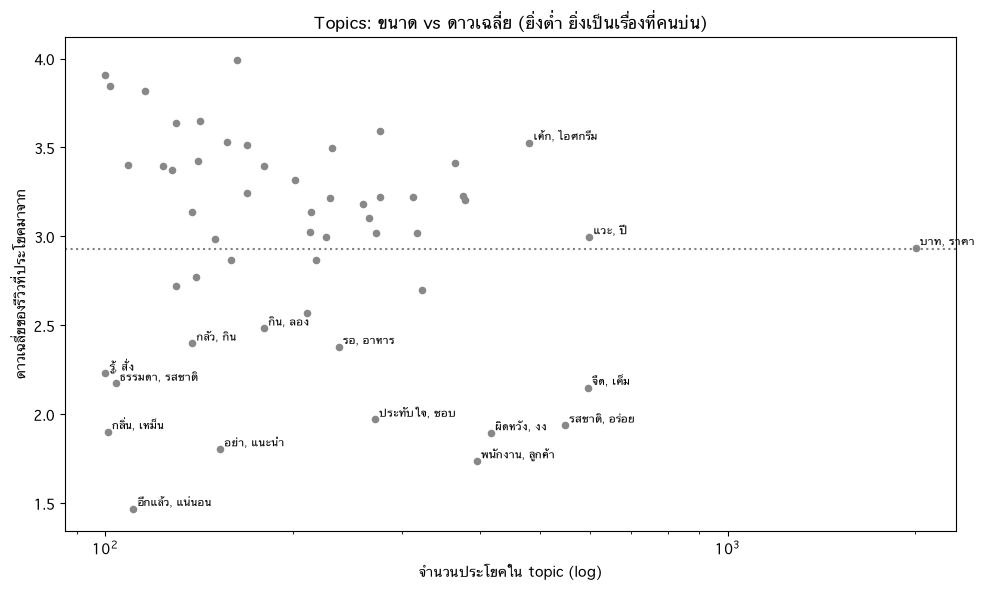

In [6]:
big = stats[stats["size"] >= 100]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(big["size"], big.mean_stars, s=20, color="#888")
for t, r in big.iterrows():
    if r.mean_stars < 2.5 or r["size"] >= 450:
        ax.annotate(top_words(t, 2), (r["size"], r.mean_stars), fontsize=8, xytext=(3, 2), textcoords="offset points")
ax.axhline(sents.stars.mean(), ls=":", c="gray")
ax.set_xscale("log")
ax.set_xlabel("จำนวนประโยคใน topic (log)")
ax.set_ylabel("ดาวเฉลี่ยของรีวิวที่ประโยคมาจาก")
ax.set_title("Topics: ขนาด vs ดาวเฉลี่ย (ยิ่งต่ำ ยิ่งเป็นเรื่องที่คนบ่น)")
plt.tight_layout()
plt.savefig(FIGS / "topics_size_vs_stars.png", dpi=120)

big.sort_values("mean_stars").head(12)[["words", "size", "mean_stars", "negative"]].round(2)

**Pain points เรียงตามดาวเฉลี่ย (ต่ำสุด)**
1. **"จะไม่กลับมาอีกแล้ว"** (1.47 ดาว) ไม่ใช่ aspect แต่เป็นสัญญาณแรงที่สุดว่ารีวิวนี้ลบ
2. **พนักงาน/บริการ** (1.74 ดาว, 395 ประโยค) เรื่องที่ทำให้ดาวต่ำที่สุดในบรรดาเรื่องที่เป็น aspect
3. "อย่า...ห้าม...แนะนำ" (1.80) เป็นการเตือนคนอื่น, "ผิดหวัง/เสียความรู้สึก" (1.89), **กลิ่นเหม็น/คาว** (1.90), **รสชาติแย่** (1.94)
4. **เนื้อสัมผัส/รสผิด** (2.15), **"ธรรมดา/ปกติ"** (2.17 ดาว) ยืนยันสิ่งที่เจอใน 01/02 ว่าคำกลางๆ คือการบ่นแบบสุภาพ, **การรอ** (2.38)

ส่วนเรื่องที่ไม่อยู่ใน 4 aspect (ตารางถัดไป) เช่น ที่จอดรถ ทำเล เวลาเปิด-ปิด ล้วนมาจากรีวิวดาว **ปกติหรือสูง**
แปลว่าเป็นข้อมูลประกอบ ไม่ใช่สาเหตุที่คนให้ดาวต่ำ **→ 4 aspect ที่เลือกไว้ครอบคลุมเรื่องที่สำคัญแล้ว** ไม่ต้องเพิ่ม aspect ใหม่

In [7]:
no_aspect = big[big[[ASPECT_NAMES_TH[a] for a in ASPECTS]].max(axis=1) < 0.2]
no_aspect.sort_values("size", ascending=False)[["words", "size", "negative", "mean_stars"]].round(2)

,words,size,negative,mean_stars
topic,,,,
1,"แวะ, ปี, ลอง, ทาน, กิน",599,0.04,3.00
5,"ผิดหวัง, งง, เสียดาย, เสียความรู้สึก, แย่มาก",416,0.43,1.89
10,"สั่ง, สั่งอาหาร, เมนู, สาม, ดังนี้",323,0.12,2.70
11,"ดาว, คะแนน, โดยรวม, เต็ม, สรุป",317,0.10,3.02
12,"ที่จอดรถ, จอด, รถ, หา, ริมถนน",312,0.01,3.22
14,"หลากหลาย, เมนู, อาหาร, เลือก, ยังมี",276,0.01,3.59
16,"ประทับใจ, ชอบ, ไหว, ปลื้ม, สรุป",271,0.54,1.97
18,"ตั้งอยู่, ตรงข้าม, ชั้น, ถนน, ซอย",259,0.01,3.18
21,"คน, ลูกค้า, เต็ม, แน่น, คิว",230,0.03,3.21


## 4. Association rules

**ไอเดีย:** มองแต่ละรีวิวเป็น "ตะกร้า" (เหมือนตะกร้าสินค้าในซูเปอร์มาร์เก็ต) ที่มี item เช่น `service:neg` (มีประโยคที่ติเรื่องบริการ) หรือ `rating:low` (1–2 ดาว)
แล้วหากฎแบบ "ถ้ามี A มักจะมี B" ด้วย **Apriori**

| ตัววัด | ความหมาย | ตัวอย่าง |
|---|---|---|
| **support** | สัดส่วนรีวิวที่มีทั้ง A และ B | 0.12 = 12% ของรีวิว |
| **confidence** | ในรีวิวที่มี A มีกี่ % ที่มี B ด้วย | P(B \| A) |
| **lift** | confidence หารด้วยอัตราปกติของ B | > 1 = A ทำให้เจอ B บ่อยกว่าปกติ, 1 = ไม่เกี่ยวกัน |

**ข้อควรระวังสามข้อ**
- item aspect มาจาก keyword × sentiment ของ baseline ซึ่งยังไม่ได้วัดความแม่น
- ตัวอย่างสุ่มดาวละเท่ากัน `rating:low` จึงมี 40% ในตัวอย่างนี้ (ของจริงใน Wongnai ~6%) ค่า confidence จึงใช้กับข้อมูลจริงตรงๆ ไม่ได้ ให้ดู lift และ **ลำดับ** ของกฎ
- association ≠ causation: `service:neg → rating:low` ไม่ได้พิสูจน์ว่าบริการแย่ **ทำให้** ดาวต่ำ

In [8]:
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

def review_items(g):
    items = {"rating:low" if g.stars.iloc[0] <= 2 else "rating:mid" if g.stars.iloc[0] == 3 else "rating:high"}
    for a in ASPECTS:
        hit = g[g[f"kw_{a}"] == 1]
        if (hit.p_pos < 0.5).any():
            items.add(f"{a}:neg")
        if (hit.p_pos >= 0.5).any():
            items.add(f"{a}:pos")
    return sorted(items)

baskets = sents.groupby("review_id").apply(review_items, include_groups=False)
te = TransactionEncoder()
X = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
print(len(X), "reviews")
X.mean().sort_values(ascending=False).round(2)

2000 reviews


taste:pos       0.80
price:pos       0.52
service:pos     0.47
ambience:pos    0.45
rating:high     0.40
rating:low      0.40
taste:neg       0.35
rating:mid      0.20
price:neg       0.15
service:neg     0.14
ambience:neg    0.06
dtype: float64

In [9]:
frequent = apriori(X, min_support=0.03, use_colnames=True)
rules = association_rules(frequent, metric="lift", min_threshold=1.0)
rules["antecedents"] = rules.antecedents.map(lambda s: " + ".join(sorted(s)))
rules["consequents"] = rules.consequents.map(lambda s: " + ".join(sorted(s)))
cols = ["antecedents", "consequents", "support", "confidence", "lift"]

to_low = rules[rules.consequents == "rating:low"].sort_values("lift", ascending=False)
to_low[cols].head(12).round(2)

,antecedents,consequents,support,confidence,lift
56,ambience:neg + taste:neg,rating:low,0.03,0.95,2.36
208,price:neg + service:neg,rating:low,0.03,0.94,2.35
326,service:neg + taste:neg,rating:low,0.06,0.88,2.20
615,ambience:pos + service:neg + taste:neg,rating:low,0.03,0.88,2.19
0,ambience:neg,rating:low,0.05,0.87,2.17
985,service:neg + service:pos + taste:neg,rating:low,0.04,0.87,2.16
41,service:neg,rating:low,0.12,0.86,2.14
320,service:neg + service:pos,rating:low,0.08,0.84,2.09
1010,service:neg + taste:neg + taste:pos,rating:low,0.04,0.84,2.09
1318,service:neg + service:pos + taste:neg + taste:pos,rating:low,0.03,0.83,2.08


**อ่านกฎ:** "ติทั้งราคาและบริการ" → ดาวต่ำ ด้วย confidence 0.94 (lift 2.35)
แปลว่า ในรีวิวที่ติสองเรื่องนี้พร้อมกัน 94% เป็นรีวิว 1–2 ดาว เทียบกับ 40% ของรีวิวทั้งหมดในตัวอย่าง

สังเกตว่ามีกฎแปลกๆ อย่าง `service:neg + service:pos` (ทั้งชมทั้งติบริการในรีวิวเดียว) ด้วย
อาจเป็นรีวิวผสมจริง ("พนักงานคนหนึ่งดี แต่อีกคนแย่") หรือ sentiment ระดับประโยคของ baseline ทายผิด ยังแยกไม่ได้จนกว่าจะมี label

In [10]:
to_high = rules[rules.consequents == "rating:high"].sort_values("lift", ascending=False)
to_high[cols].head(8).round(2)

,antecedents,consequents,support,confidence,lift
463,ambience:pos + price:pos + service:pos,rating:high,0.08,0.49,1.23
1043,ambience:pos + price:pos + service:pos + taste...,rating:high,0.08,0.49,1.23
88,ambience:pos + price:pos,rating:high,0.12,0.48,1.20
474,ambience:pos + price:pos + taste:pos,rating:high,0.11,0.48,1.19
586,ambience:pos + service:pos + taste:pos,rating:high,0.11,0.47,1.19
126,ambience:pos + taste:pos,rating:high,0.18,0.47,1.18
122,ambience:pos + service:pos,rating:high,0.12,0.46,1.14
826,price:pos + service:pos + taste:pos,rating:high,0.11,0.45,1.14


**กฎที่นำไปสู่ดาวสูงอ่อนมาก** (lift สูงสุดแค่ 1.23) เพราะ **คำชมมีอยู่ทุกที่**
`taste:pos` อยู่ใน 80% ของรีวิว รวมถึงรีวิวดาวต่ำ (คนมักชมอะไรสักอย่างก่อนบ่น อย่างที่เห็นใน error analysis ของ 02)
คำชมจึงไม่ช่วยแยกรีวิวดี แต่ **คำติแยกได้ชัด**

เทียบกฎแบบ item เดียว: ติเรื่องไหนแล้วดาวต่ำบ่อยที่สุด

In [11]:
single = rules[(rules.consequents == "rating:low") & ~rules.antecedents.str.contains(r"\+")]
single = single[single.antecedents.str.endswith(":neg")].sort_values("lift", ascending=False)
single[cols].round(2)

,antecedents,consequents,support,confidence,lift
0,ambience:neg,rating:low,0.05,0.87,2.17
41,service:neg,rating:low,0.12,0.86,2.14
20,price:neg,rating:low,0.11,0.72,1.81
44,taste:neg,rating:low,0.25,0.72,1.79


| ติเรื่อง | อยู่ในกี่ % ของรีวิว (support) | ถ้าติเรื่องนี้ เป็นดาวต่ำกี่ % (confidence) |
|---|---|---|
| อาหาร | 25% | 72% |
| ราคา | 11% | 72% |
| บริการ | 12% | 86% |
| บรรยากาศ | 5% | 87% |

**insight:** คนติเรื่อง **อาหารบ่อยที่สุด** แต่ติแล้วยังให้ดาวปานกลางได้
ส่วนเรื่อง **บริการ** ถูกติน้อยกว่าครึ่งหนึ่ง แต่ถ้าโดนติเมื่อไร **86% เป็นรีวิว 1–2 ดาว**
สอดคล้องกับ topic "พนักงาน/บริการ" ที่ดาวเฉลี่ยต่ำที่สุดในบรรดา aspect (1.74)
(บรรยากาศมี confidence สูงสุดแต่ support แค่ 5% คือ ~100 รีวิว ตัวเลขจึงแกว่งได้มาก)

In [12]:
out = ROOT / "reports" / "topics.csv"
stats.sort_values("size", ascending=False).round(3).to_csv(out)
print("saved", out)

saved /Users/riewta/Downloads/mlproj/reports/topics.csv


## 5. สรุป

| คำถาม | คำตอบ (จากตัวอย่าง 2,000 รีวิว) |
|---|---|
| 4 aspect พอไหม | พอ topic ที่อยู่นอก aspect (ที่จอดรถ, ทำเล, เวลาเปิด) มาจากรีวิวดาวปกติ ไม่ใช่สาเหตุของดาวต่ำ |
| เรื่องไหนทำให้ดาวต่ำที่สุด | **บริการ**: topic ดาวเฉลี่ย 1.74, ติแล้ว 86% เป็นดาวต่ำ |
| เรื่องไหนถูกพูดถึงบ่อยที่สุด | **อาหาร** ทั้งชมและติ แต่ติอาหารอย่างเดียวยังไม่ตัดสินดาว |
| คำชมช่วยทำนายดาวสูงไหม | แทบไม่ช่วย (lift ≤ 1.23) เพราะอยู่ในรีวิวแทบทุกแบบ |

**สิ่งที่ dashboard (Phase 4) ควรแสดงจากผลนี้:** สัดส่วนคำติแยกตาม aspect (ไม่ใช่แค่จำนวนที่ถูกพูดถึง) และ topic ย่อยของคำติ
พร้อมประโยคตัวอย่าง เพราะ "บริการแย่" บอกเจ้าของร้านได้น้อยกว่า "พนักงานไม่สนใจลูกค้า" หรือ "รอ 40 นาที"

**ทุกตัวเลขในส่วน aspect × sentiment ยังรอการตรวจสอบด้วย label** (`data/labels/aspect_sentences.csv`)
ส่วนที่มาจากข้อมูลจริง (ดาวเฉลี่ยต่อ topic) เชื่อถือได้มากกว่า

ตาราง topic ทั้งหมดอยู่ที่ `reports/topics.csv`